In [3]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


In [4]:
data_dir =r'D:\Umesh-MAY2022\Datasets\PetImages'

In [5]:
train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    image_size=(128,128),
    batch_size=32,
    shuffle=True
)

class_names = train_ds.class_names
print("Classes:", class_names)

Found 24824 files belonging to 2 classes.
Classes: ['Cat', 'Dog']


Class names: ['Cat', 'Dog']


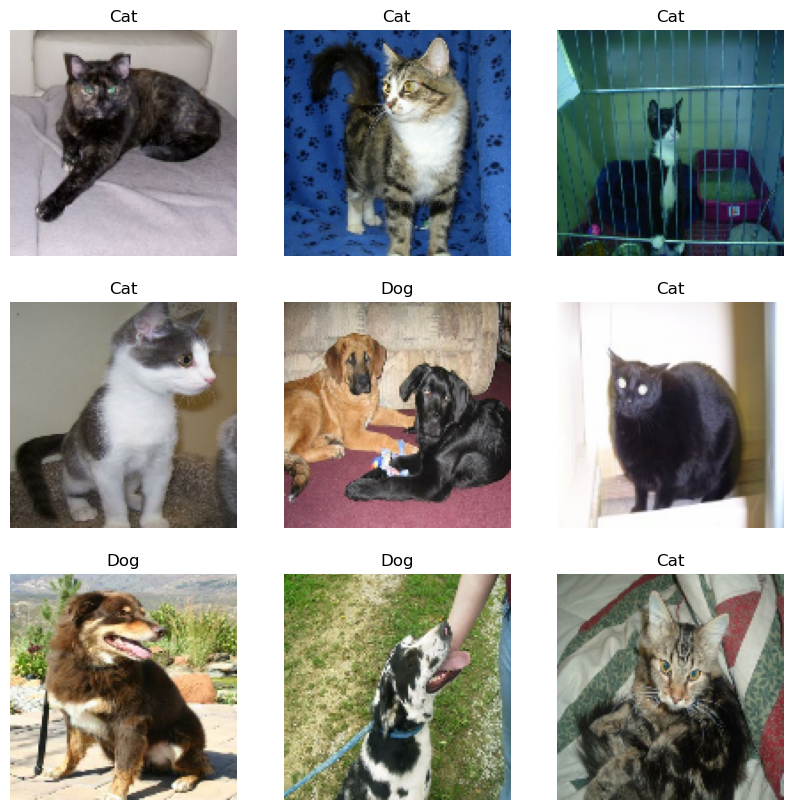

In [7]:
import matplotlib.pyplot as plt
import tensorflow as tf

# Class names
class_names = train_ds.class_names
print("Class names:", class_names)

# Take one batch
images, labels = next(iter(train_ds))

# Plot first 9 images
plt.figure(figsize=(10, 10))
for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(class_names[labels[i]])
    plt.axis("off")
plt.show()


In [9]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Building a simple CNN model with comments explaining each layer
model = keras.Sequential([
    
    # 1. Input layer: expects images of size 128x128 with 3 color channels (RGB)
    layers.Input(shape=(128, 128, 3)),
    
    # 2. Convolution layer: applies 32 filters of size 3x3 to detect features (edges, textures)
    layers.Conv2D(32, (3,3), activation='relu'),
    
    # 3. Max Pooling: reduces spatial size by taking max value in each 2x2 region
    layers.MaxPooling2D((2,2)),
    
    # 4. Second convolution: applies 64 filters of size 3x3 to detect deeper, more complex features
    layers.Conv2D(64, (3,3), activation='relu'),
    
    # 5. Second pooling: again reduces spatial dimensions, keeps strongest features
    layers.MaxPooling2D((2,2)),
    
    # 6. Flatten: converts 2D feature maps into a 1D vector for the dense layers
    layers.Flatten(),
    
    # 7. Dense layer: fully connected layer with 128 neurons to learn high-level combinations of features
    layers.Dense(128, activation='relu'),
    
    # 8. Output layer: 1 neuron with sigmoid activation for binary classification (cat vs dog)
    layers.Dense(1, activation='sigmoid')
])

# Print model summary to show output shapes at each layer
model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 57600)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │       7,372,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 7,392,449 (28.20 MB)

 Trainable params: 7,392,449 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
# -----------------------------
# Compile the model
# -----------------------------
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Print model summary
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 57600)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │       7,372,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 7,392,449 (28.20 MB)

 Trainable params: 7,392,449 (28.20 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:

data_dir =r'D:\Umesh-MAY2022\Datasets\PetImages'

# -----------------------------
# Load dataset from directory
# -----------------------------
dataset = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,          # replace this
    image_size=(128, 128),        # resize all images
    batch_size=32,                # batch size
    shuffle=True                  # shuffle images
)

# Print class names
print("Class names:", dataset.class_names)

# -----------------------------
# Split into train & validation
# -----------------------------
train_size = int(0.8 * len(dataset))   # 80% training
val_size = int(0.2 * len(dataset))     # 20% validation

train_ds = dataset.take(train_size)
val_ds = dataset.skip(train_size)

print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))

# -----------------------------
# Normalize pixel values
# -----------------------------
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))

# -----------------------------
# Prefetch for performance
# -----------------------------
train_ds = train_ds.prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=tf.data.AUTOTUNE)

# -----------------------------
# Inspect one batch
# -----------------------------
for images, labels in train_ds.take(1):
    print("Batch image shape:", images.shape)
    print("Batch label shape:", labels.shape)

Found 24824 files belonging to 2 classes.
Class names: ['Cat', 'Dog']
Training batches: 620
Validation batches: 156
Batch image shape: (32, 128, 128, 3)
Batch label shape: (32,)


In [13]:
# -----------------------------
# Train the CNN model
# -----------------------------
history = model.fit(
    train_ds,                 # training dataset
    validation_data=val_ds,   # validation dataset
    epochs=10                 # number of epochs
)

# -----------------------------
# Print final training results
# -----------------------------
print("Training complete!")
print("Final training accuracy:", history.history['accuracy'][-1])
print("Final validation accuracy:", history.history['val_accuracy'][-1])


Epoch 1/10


C:\Users\phdst\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


620/620 ━━━━━━━━━━━━━━━━━━━━ 307s 492ms/step - accuracy: 0.6602 - loss: 0.6141 - val_accuracy: 0.7362 - val_loss: 0.5220
Epoch 2/10
620/620 ━━━━━━━━━━━━━━━━━━━━ 60s 96ms/step - accuracy: 0.7650 - loss: 0.4798 - val_accuracy: 0.7594 - val_loss: 0.4937
Epoch 3/10
620/620 ━━━━━━━━━━━━━━━━━━━━ 62s 99ms/step - accuracy: 0.8370 - loss: 0.3569 - val_accuracy: 0.7799 - val_loss: 0.5093
Epoch 4/10
620/620 ━━━━━━━━━━━━━━━━━━━━ 60s 97ms/step - accuracy: 0.9092 - loss: 0.2217 - val_accuracy: 0.7600 - val_loss: 0.6223
Epoch 5/10
620/620 ━━━━━━━━━━━━━━━━━━━━ 61s 98ms/step - accuracy: 0.9587 - loss: 0.1099 - val_accuracy: 0.7833 - val_loss: 0.7180
Epoch 6/10
620/620 ━━━━━━━━━━━━━━━━━━━━ 60s 97ms/step - accuracy: 0.9778 - loss: 0.0632 - val_accuracy: 0.7721 - val_loss: 0.9682
Epoch 7/10
620/620 ━━━━━━━━━━━━━━━━━━━━ 60s 97ms/step - accuracy: 0.9871 - loss: 0.0458 - val_accuracy: 0.7733 - val_loss: 0.9120
Epoch 8/10
620/620 ━━━━━━━━━━━━━━━━━━━━ 60s 97ms/step - accuracy: 0.9919 - loss: 0.0272 - val_accur

## Plot Accuracy & Loss Curves

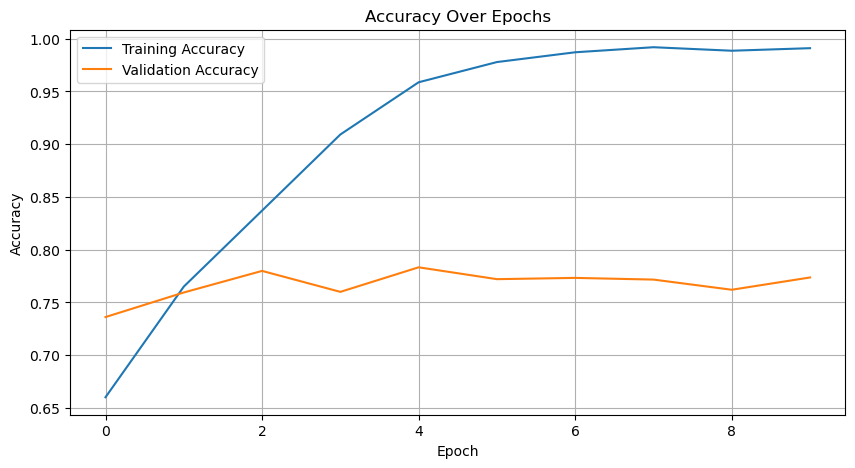

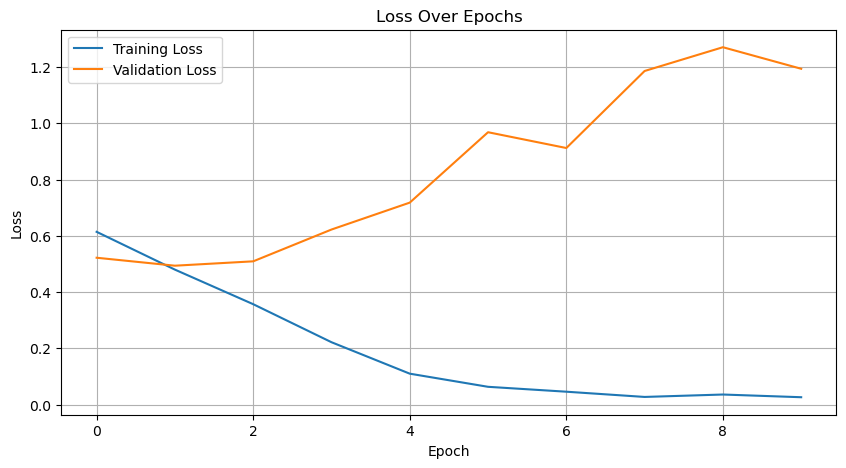

In [14]:
import matplotlib.pyplot as plt

# -----------------------------
# Plot Accuracy
# -----------------------------
plt.figure(figsize=(10,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# -----------------------------
# Plot Loss
# -----------------------------
plt.figure(figsize=(10,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()


## Predict on test Images & Display It

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step


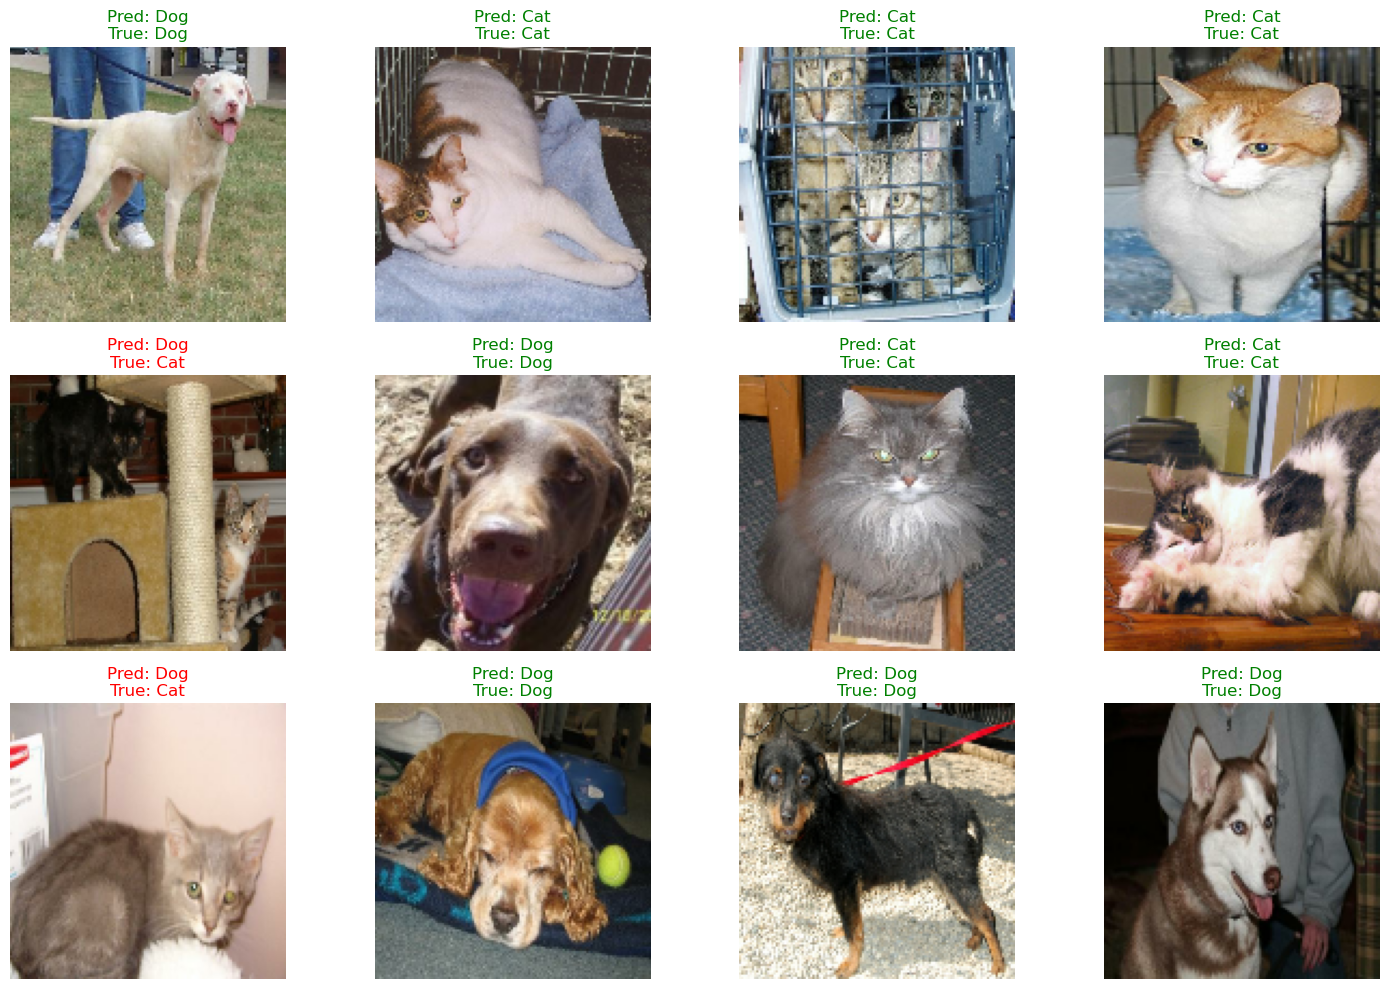

In [17]:
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------------
# Get one batch from validation set
# -----------------------------------
val_images, val_labels = next(iter(val_ds))

# Run predictions on this batch
pred_probs = model.predict(val_images)
pred_labels = (pred_probs.flatten() > 0.5).astype(int)  # 1 = dog, 0 = cat

# Class names from dataset
class_names = dataset.class_names  # e.g., ['cats', 'dogs']

# -----------------------------------
# Plot 12 images with predicted vs actual
# -----------------------------------
plt.figure(figsize=(15, 10))
num_images = 12

for i in range(num_images):
    img = val_images[i].numpy()
    true_label = int(val_labels[i].numpy())
    pred_label = int(pred_labels[i])

    plt.subplot(3, 4, i + 1)
    plt.imshow(img)
    plt.axis("off")

    title = f"Pred: {class_names[pred_label]}\nTrue: {class_names[true_label]}"
    color = "green" if pred_label == true_label else "red"
    plt.title(title, color=color)

plt.tight_layout()
plt.show()


## Confusion Matrix + ROC Curve

In [19]:
## Collect all validation predictions

In [18]:
import numpy as np

# Collect all validation images and labels
y_true = []
y_pred = []

for images, labels in val_ds:
    preds = model.predict(images).flatten()
    y_true.extend(labels.numpy())
    y_pred.extend(preds)

y_true = np.array(y_true)
y_pred = np.array(y_pred)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
1/1 ━━━━━━━

### Confusion Matrix

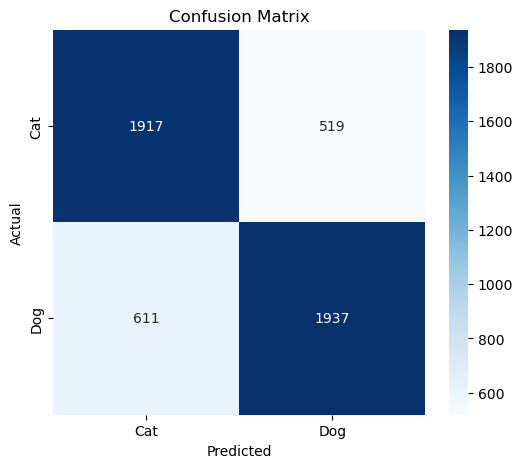

In [20]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Convert probabilities to class labels
y_pred_labels = (y_pred > 0.5).astype(int)

cm = confusion_matrix(y_true, y_pred_labels)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=dataset.class_names,
            yticklabels=dataset.class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


### ROC Curve and AUC Score

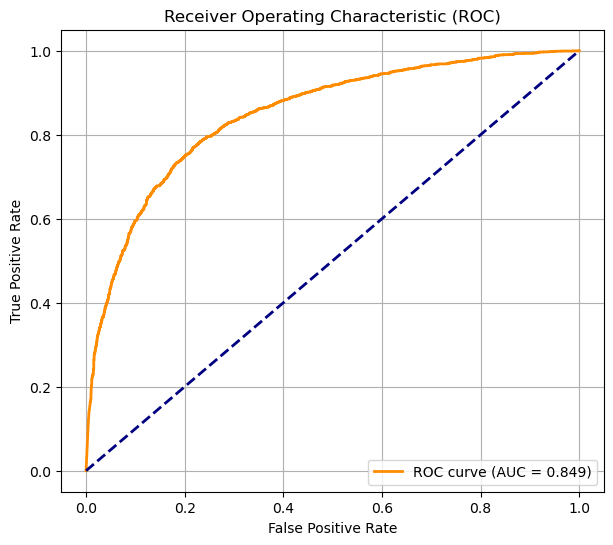

AUC Score: 0.8487727745512755


In [21]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_true, y_pred)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))
plt.plot(fpr, tpr, color='darkorange', lw=2,
         label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC)")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

print("AUC Score:", roc_auc)
